## Carga y comprension del dataset

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# configuracion visualizacion
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', "{:.6f}".format)

# raiz del proyecto
cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        ruta
        for ruta in (cwd, *cwd.parents)
        if (ruta / "data" / "interim").is_dir()
        and (ruta / "notebooks").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se pudo localizar la raíz del proyecto."
    )

# Directorio de datos
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

# Cargar panel
panel = pd.read_parquet(
    INTERIM_DIR / "panel_bancario_2026_09.parquet"
)

# Asegurar formato de fechas
panel["fecha"] = pd.to_datetime(panel["fecha"])

# Ordenar observaciones
panel = (
    panel
    .sort_values(["banco", "fecha"])
    .reset_index(drop=True)
)

print("Dimensiones:", panel.shape)
print("Instituciones:", panel["banco"].nunique())

print("\nPeríodo histórico:")
print("Inicio:", panel["fecha"].min())
print("Fin:", panel["fecha"].max())

print("\nDuplicados banco-mes:")
print(panel.duplicated(["banco", "fecha"]).sum())

display(panel.head())

Dimensiones: (5972, 11)
Instituciones: 23

Período histórico:
Inicio: 2003-01-01 00:00:00
Fin: 2026-09-01 00:00:00

Duplicados banco-mes:
0


,fecha,banco,solvencia,liquidez,roa,roe,cartera_depositos,cartera_bruta,cartera_improductiva,morosidad_total,cobertura
0,2011-07-01,BANCO ATLANTIDA S.A.,NaN,0.000000,0.019541,0.091531,0.000000,31872.724310,828.743660,0.026002,0.776931
1,2011-08-01,BANCO ATLANTIDA S.A.,0.251770,0.000000,0.018258,0.085764,0.000000,33162.498160,728.989740,0.021982,1.002009
2,2011-09-01,BANCO ATLANTIDA S.A.,0.288140,0.000000,0.017008,0.081672,0.000000,34827.652490,822.659430,0.023621,1.003828
3,2011-10-01,BANCO ATLANTIDA S.A.,0.269500,0.000000,0.016025,0.073058,0.000000,36890.476810,909.871570,0.024664,1.026205
4,2011-11-01,BANCO ATLANTIDA S.A.,0.260570,0.000000,0.015737,0.070117,0.000000,38955.554030,1020.616170,0.026200,1.007305


### Cuantos bancos privados disponen de informacion en cada mes del periodo historico

Trabajaremos con un panel desbalanceado, tenemos bancos con menor informacion que otros

In [2]:
# Cantidad de instituciones con registros por mes
cobertura_mensual = (
    panel
    .groupby("fecha")
    .agg(
        bancos_disponibles=("banco", "nunique"),
        observaciones=("banco", "size"),
        morosidad_disponible=("morosidad_total", "count")
    )
    .reset_index()
)

print("Resumen de cobertura mensual:")

display(cobertura_mensual.head(10))
display(cobertura_mensual.tail(10))

print("\nEstadísticas de cobertura:")

display(
    cobertura_mensual[
        ["bancos_disponibles", "morosidad_disponible"]
    ].describe()
)

Resumen de cobertura mensual:


,fecha,bancos_disponibles,observaciones,morosidad_disponible
0,2003-01-01,18,18,18
1,2003-02-01,18,18,18
2,2003-03-01,18,18,18
3,2003-04-01,18,18,18
4,2003-05-01,18,18,18
5,2003-06-01,18,18,18
6,2003-07-01,18,18,18
7,2003-08-01,18,18,18
8,2003-09-01,18,18,18
9,2003-10-01,18,18,18


,fecha,bancos_disponibles,observaciones,morosidad_disponible
275,2025-12-01,23,23,23
276,2026-01-01,23,23,23
277,2026-02-01,23,23,23
278,2026-03-01,23,23,23
279,2026-04-01,23,23,23
280,2026-05-01,23,23,23
281,2026-06-01,23,23,23
282,2026-07-01,23,23,23
283,2026-08-01,23,23,23
284,2026-09-01,23,23,23



Estadísticas de cobertura:


,bancos_disponibles,morosidad_disponible
count,285.000000,285.000000
mean,20.954386,20.933333
std,1.825491,1.853559
min,18.000000,18.000000
25%,19.000000,19.000000
50%,21.000000,21.000000
75%,23.000000,23.000000
max,23.000000,23.000000


## evolucion de la cobertura mensual

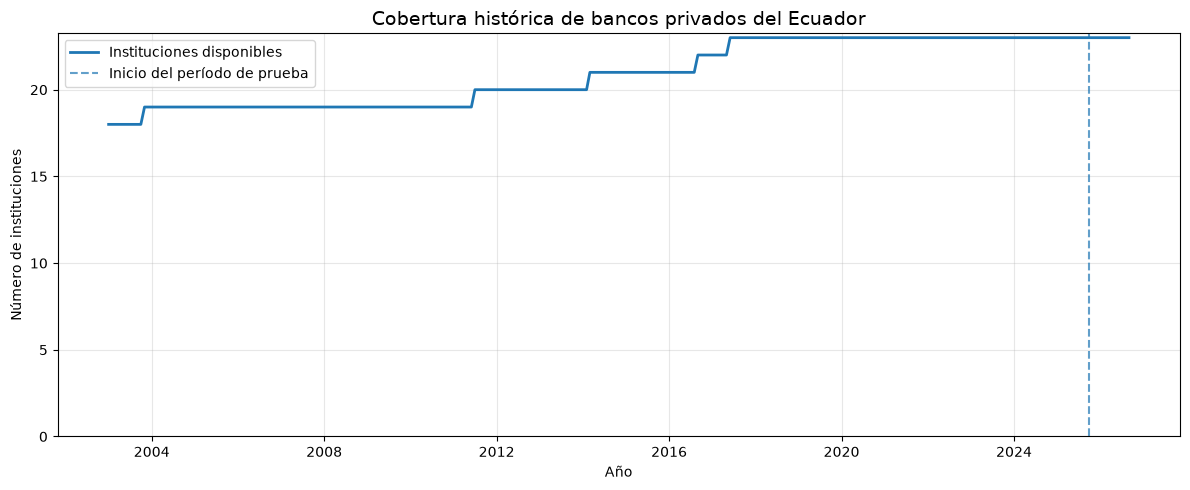

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    cobertura_mensual["fecha"],
    cobertura_mensual["bancos_disponibles"],
    linewidth=2,
    label="Instituciones disponibles"
)

ax.axvline(
    pd.Timestamp("2025-10-01"),
    linestyle="--",
    alpha=0.7,
    label="Inicio del período de prueba"
)

ax.set_title(
    "Cobertura histórica de bancos privados del Ecuador",
    fontsize=14
)

ax.set_xlabel("Año")
ax.set_ylabel("Número de instituciones")

ax.set_ylim(bottom=0)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

desde el 2018 tenemos la informacion de todos los bancos. En 2003 tenemos informacion desde los 18 bancos

## estudio de la variable objetivo Morosidad bancaria

morosidad = cartera improductiva / cartera bruta

Como se distribuye historicamente la morosidad de los bancos privados ecuatorianos y que tan frecuentes son los valores extremos?

Separar el periodo de desarrollo con el de prueba
Desarrollo hasta el 2025-08-01, a partir de esa fecha, prueba

In [4]:
# Separar el período de desarrollo
fecha_corte = pd.Timestamp("2025-09-01")

desarrollo = panel.loc[
    panel["fecha"] <= fecha_corte
].copy()

# Convertir morosidad a puntos porcentuales
desarrollo["morosidad_pp"] = (
    desarrollo["morosidad_total"] * 100
)

# Información general
print("Observaciones de desarrollo:", len(desarrollo))

print(
    "Instituciones:",
    desarrollo["banco"].nunique()
)

print(
    "Morosidad disponible:",
    desarrollo["morosidad_pp"].notna().sum()
)

# Estadísticas descriptivas
estadisticas = desarrollo["morosidad_pp"].describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99
    ]
)

display(estadisticas)

Observaciones de desarrollo: 5696
Instituciones: 23
Morosidad disponible: 5690


count   5690.000000
mean       4.837328
std        6.071565
min        0.000000
1%         0.000001
5%         0.189938
25%        1.937143
50%        3.620592
75%        5.994109
95%       11.891839
99%       27.430599
max       87.043435
Name: morosidad_pp, dtype: float64

Distribucion de la variable

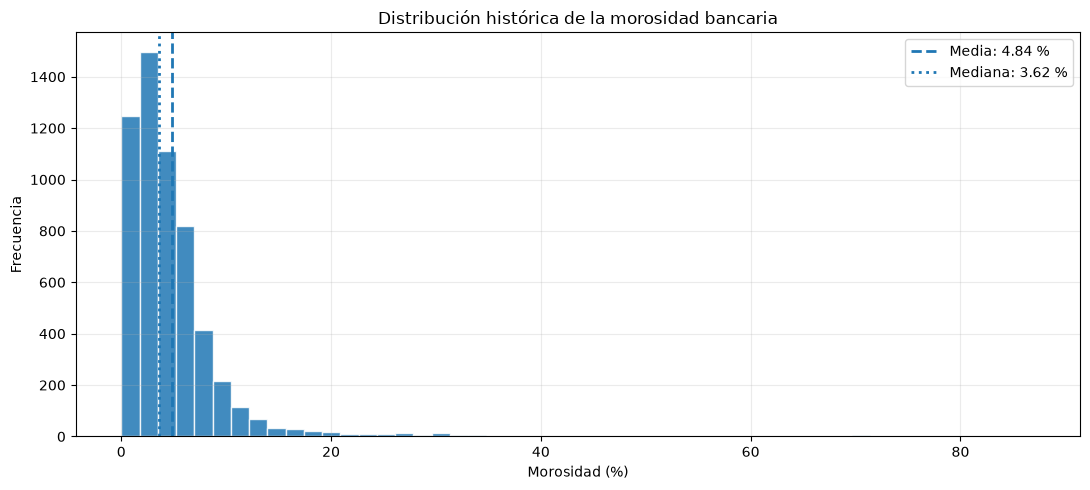

In [5]:
# Seleccionar observaciones válidas
morosidad = desarrollo["morosidad_pp"].dropna()

# Crear gráfico
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    morosidad,
    bins=50,
    edgecolor="white",
    alpha=0.85
)

# Media y mediana
media = morosidad.mean()
mediana = morosidad.median()

ax.axvline(
    media,
    linestyle="--",
    linewidth=2,
    label=f"Media: {media:.2f} %"
)

ax.axvline(
    mediana,
    linestyle=":",
    linewidth=2,
    label=f"Mediana: {mediana:.2f} %"
)

ax.set_title(
    "Distribución histórica de la morosidad bancaria"
)

ax.set_xlabel("Morosidad (%)")
ax.set_ylabel("Frecuencia")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

La distribución histórica de la morosidad bancaria presenta una marcada asimetría positiva, con una media de 4,84 % y una mediana de 3,62 %. La mayoría de las observaciones se concentra en niveles relativamente moderados, aunque existen valores extremos que alcanzan el 87,04 %. Estos resultados sugieren una considerable heterogeneidad en el comportamiento de la morosidad, por lo que resulta necesario analizar las diferencias entre instituciones y examinar los valores atípicos antes del modelado.

### Que diferencias existen en los niveles y la variabilidad de la morosidad entre las instituciones financieras ecuatorianas?

In [6]:
# Estadísticas descriptivas de morosidad por institución

resumen_bancos = (
    desarrollo
    .groupby("banco")["morosidad_pp"]
    .agg(
        observaciones="count",
        media="mean",
        mediana="median",
        desviacion="std",
        minimo="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        p95=lambda x: x.quantile(0.95),
        maximo="max"
    )
)

# Calcular el rango intercuartílico
resumen_bancos["iqr"] = (
    resumen_bancos["q3"] - resumen_bancos["q1"]
)

# Ordenar por mediana
resumen_bancos = resumen_bancos.sort_values(
    "mediana",
    ascending=False
)

display(resumen_bancos.round(3))

,observaciones,media,mediana,desviacion,minimo,q1,q3,p95,maximo,iqr
banco,,,,,,,,,,
BP LITORAL,273,8.791000,8.800000,3.416000,2.614000,6.076000,10.979000,14.713000,20.284000,4.903000
BP CAPITAL,273,15.099000,8.308000,19.139000,1.591000,5.261000,12.749000,70.416000,87.043000,7.488000
"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODESARROLLO",139,7.195000,7.230000,1.242000,5.045000,6.024000,8.066000,9.292000,9.982000,2.042000
BANCO ATLANTIDA S.A.,171,9.171000,7.048000,4.755000,2.198000,6.138000,12.501000,18.416000,22.198000,6.363000
BANCO COMERCIAL DE MANABI,273,6.783000,6.523000,2.693000,1.693000,4.985000,8.461000,10.983000,15.792000,3.476000
BP SOLIDARIO,273,6.365000,6.217000,1.671000,0.856000,5.396000,7.571000,9.051000,11.656000,2.175000
BP AUSTRO,273,6.887000,5.635000,4.438000,2.380000,4.402000,7.071000,17.173000,30.448000,2.669000
BP AMAZONAS,273,4.842000,4.754000,1.516000,0.746000,3.660000,5.825000,7.312000,9.942000,2.165000
BP VISIONFUND ECUADOR S.A.,109,4.589000,4.695000,1.356000,2.433000,3.415000,5.761000,6.719000,7.281000,2.345000


/tmp/ipykernel_12617/3995149131.py:21: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


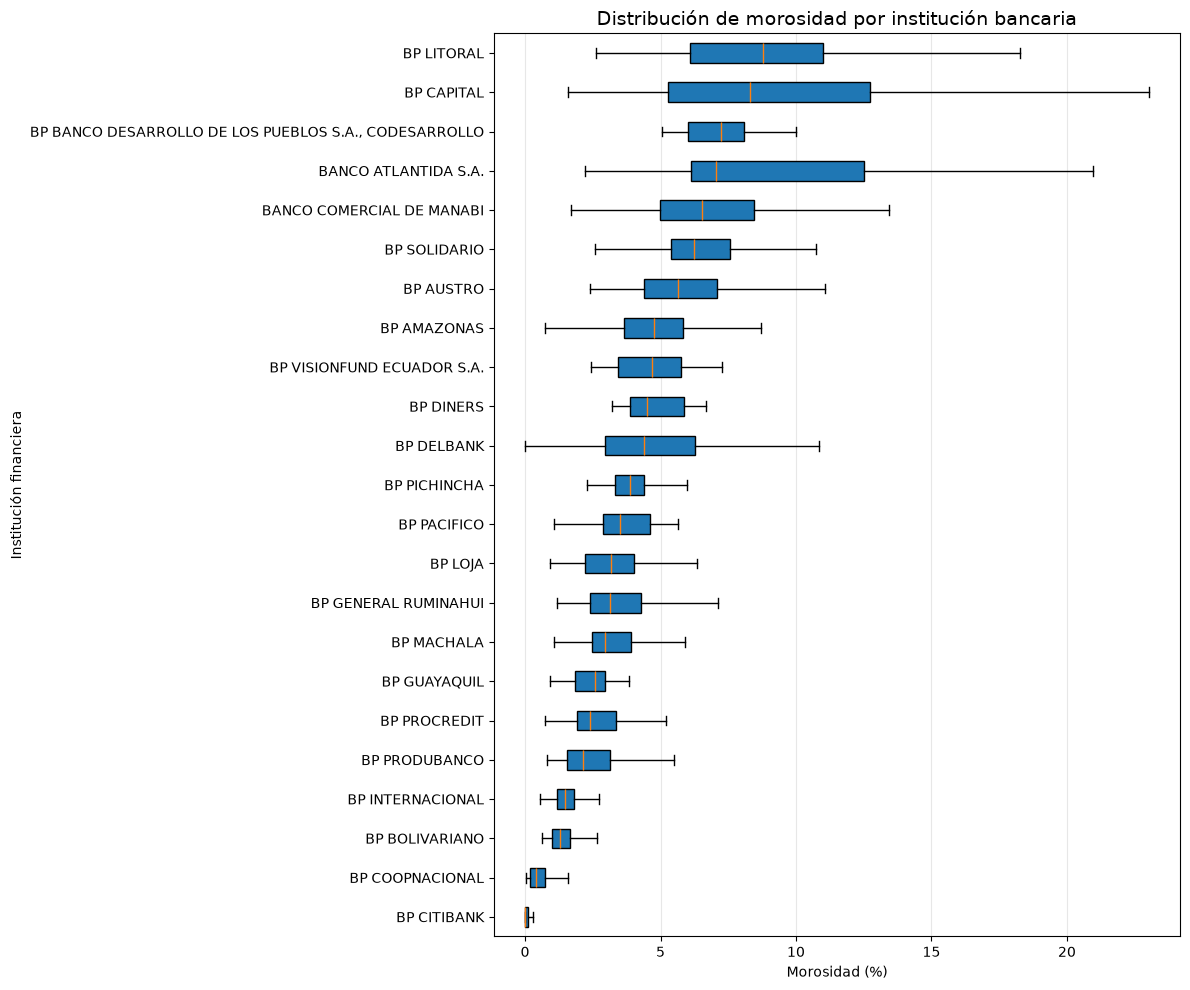

In [7]:
# Ordenar instituciones según su mediana
bancos_ordenados = (
    resumen_bancos
    .sort_values("mediana")
    .index
    .tolist()
)

# Preparar los datos para los boxplots
datos_boxplot = [
    desarrollo.loc[
        desarrollo["banco"] == banco,
        "morosidad_pp"
    ].dropna().to_numpy()
    for banco in bancos_ordenados
]

# Crear figura
fig, ax = plt.subplots(figsize=(12, 10))

ax.boxplot(
    datos_boxplot,
    vert=False,
    showfliers=False,
    patch_artist=True
)

ax.set_yticks(
    range(1, len(bancos_ordenados) + 1),
    labels=bancos_ordenados
)

ax.set_title(
    "Distribución de morosidad por institución bancaria",
    fontsize=14
)

ax.set_xlabel("Morosidad (%)")
ax.set_ylabel("Institución financiera")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Identificar las 15 observaciones con mayor morosidad

valores_extremos = (
    desarrollo
    .nlargest(
        15,
        "morosidad_pp"
    )
    [
        [
            "fecha",
            "banco",
            "morosidad_pp",
            "cartera_bruta",
            "cartera_improductiva"
        ]
    ]
)

display(valores_extremos)

,fecha,banco,morosidad_pp,cartera_bruta,cartera_improductiva
1671,2019-06-01,BP CAPITAL,87.043435,8643.697660,7523.771390
1670,2019-05-01,BP CAPITAL,86.219913,8872.954630,7650.253740
1669,2019-04-01,BP CAPITAL,85.068776,9099.717950,7741.018670
1668,2019-03-01,BP CAPITAL,84.987768,9431.920950,8015.979110
1666,2019-01-01,BP CAPITAL,84.347478,10873.695800,9171.688140
1667,2019-02-01,BP CAPITAL,83.352256,9832.961740,8195.995470
1672,2019-07-01,BP CAPITAL,82.413760,8946.352890,7373.025800
1665,2018-12-01,BP CAPITAL,80.737292,10129.267120,8178.096010
1673,2019-08-01,BP CAPITAL,79.921933,9104.267810,7276.306810
1664,2018-11-01,BP CAPITAL,75.886162,9133.254220,6930.876080


## Evolucion temporal de la morosidad

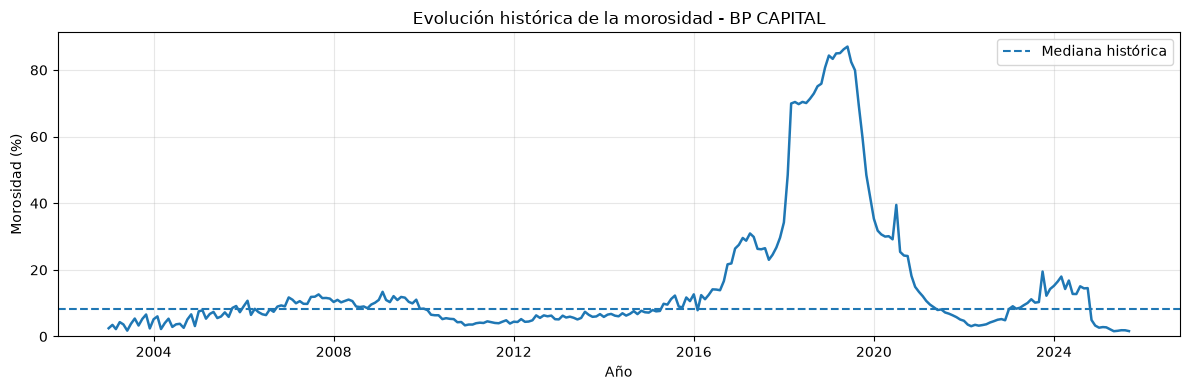

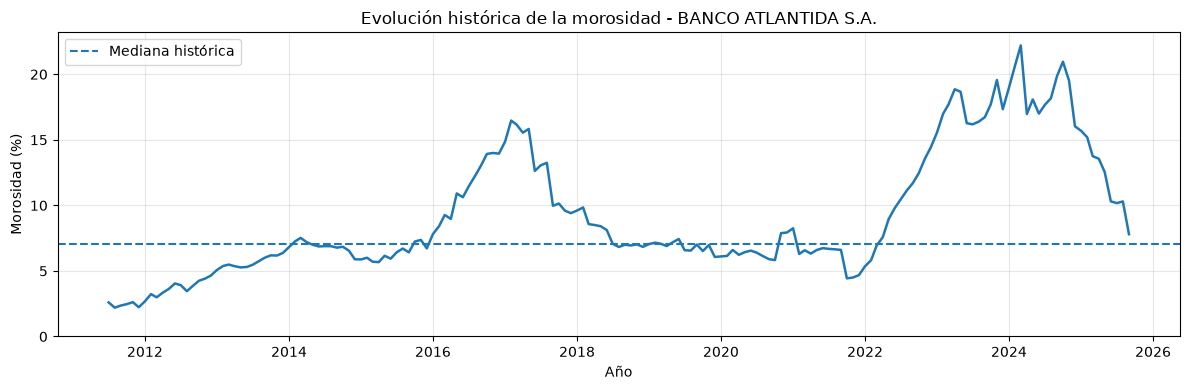

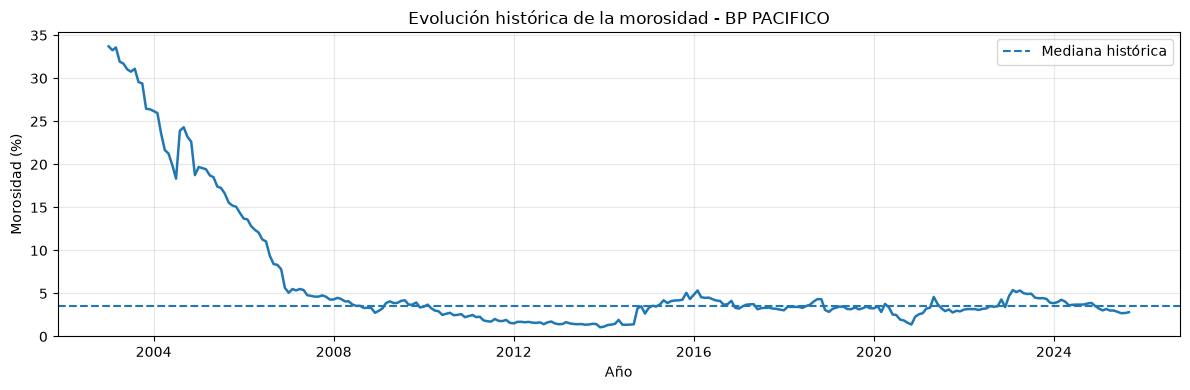

In [9]:
# Instituciones seleccionadas
bancos_analisis = [
    "BP CAPITAL",
    "BANCO ATLANTIDA S.A.",
    "BP PACIFICO"
]

for banco in bancos_analisis:

    df_banco = (
        desarrollo.loc[
            desarrollo["banco"] == banco
        ]
        .sort_values("fecha")
    )

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(
        df_banco["fecha"],
        df_banco["morosidad_pp"],
        linewidth=1.8
    )

    ax.axhline(
        df_banco["morosidad_pp"].median(),
        linestyle="--",
        label="Mediana histórica"
    )

    ax.set_title(
        f"Evolución histórica de la morosidad - {banco}"
    )

    ax.set_xlabel("Año")
    ax.set_ylabel("Morosidad (%)")

    ax.set_ylim(bottom=0)

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

## Investigar la cartera bruta e improductiva de banco capital

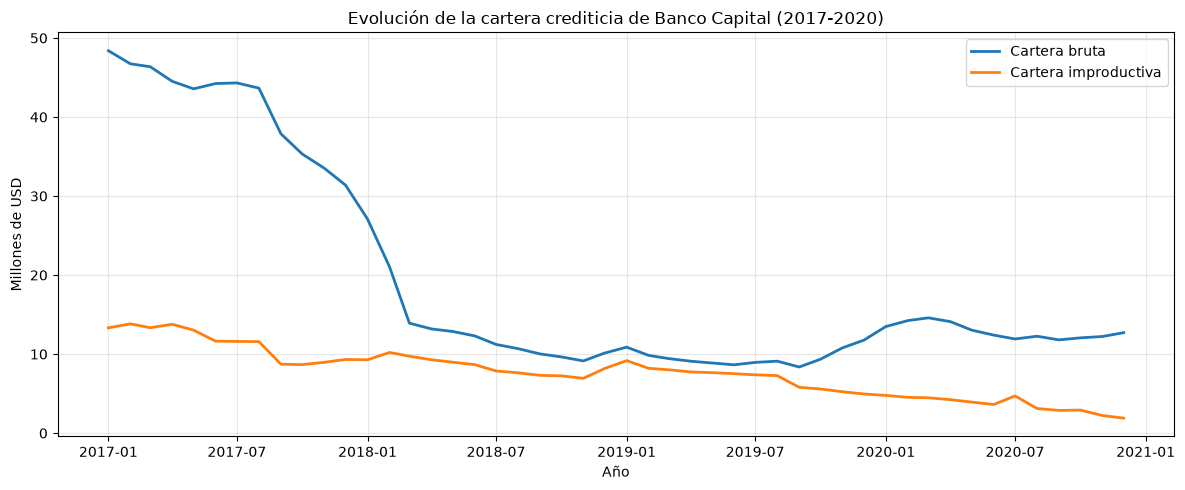

In [10]:
# Seleccionar Banco Capital
capital = desarrollo.loc[
    (desarrollo["banco"] == "BP CAPITAL")
    & desarrollo["fecha"].between(
        "2017-01-01",
        "2020-12-01"
    )
].copy()

# Convertir miles de USD a millones de USD
capital["cartera_bruta_millones"] = (
    capital["cartera_bruta"] / 1000
)

capital["cartera_improductiva_millones"] = (
    capital["cartera_improductiva"] / 1000
)

# Visualizar evolución de ambas carteras
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    capital["fecha"],
    capital["cartera_bruta_millones"],
    label="Cartera bruta",
    linewidth=2
)

ax.plot(
    capital["fecha"],
    capital["cartera_improductiva_millones"],
    label="Cartera improductiva",
    linewidth=2
)

ax.set_title(
    "Evolución de la cartera crediticia de Banco Capital (2017-2020)"
)

ax.set_xlabel("Año")
ax.set_ylabel("Millones de USD")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

El análisis por institución evidencia una considerable heterogeneidad en la distribución histórica de la morosidad bancaria. Banco Capital presenta la mayor dispersión y concentra los valores más extremos, alcanzando una morosidad máxima del 87,04 % durante junio de 2019. Estos valores forman parte de un episodio prolongado entre 2018 y 2019, por lo que no corresponden a una observación aislada.
Banco Atlántida presenta niveles relativamente elevados de morosidad y una dispersión apreciable, aunque sin alcanzar los extremos de Banco Capital. Asimismo, Banco Pacífico muestra una diferencia importante entre su media y mediana, lo que sugiere la presencia de períodos de deterioro crediticio.
Estos resultados justifican realizar un análisis temporal individualizado y conservar las observaciones extremas financieramente verificadas. Para el posterior modelado será necesario evaluar el desempeño por institución y examinar si los errores predictivos aumentan durante episodios de morosidad elevada.